In [2]:
import os

# Byter arbetskatalog från notebooks till projektroten, så att Python kan hitta både src/ och data/
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Kontrollerar vilken mapp Python arbetar från
print(os.getcwd())

c:\Users\almav\OneDrive\Desktop\GrupparbeteDSProjekt\data-science-group-project


In [3]:
from src.data_split import load_cleaned_data, get_splits

# Läser in den rensade datan från data/processed/
df = load_cleaned_data()

# Kontrollerar datasetets storlek
print("Antal bokningar:", df.shape[0])
print("Antal kolumner:", df.shape[1])

# Visar fem slumpmässiga bokningar
df.sample(5, random_state=42).T

2026-10-17 11:57:00 [INFO] src.data_split: Läser in städad data från data\processed\hotel_bookings_cleaned.csv
Antal bokningar: 110432
Antal kolumner: 34


,2448,31119,80453,20974,68463
hotel,Resort Hotel,Resort Hotel,City Hotel,Resort Hotel,City Hotel
is_canceled,1,0,0,0,0
lead_time,112,152,73,2,0
arrival_date_year,2016,2017,2016,2016,2015
arrival_date_month,February,April,May,June,August
arrival_date_week_number,7,14,21,23,35
arrival_date_day_of_month,12,5,18,1,27
stays_in_weekend_nights,0,0,0,0,0
stays_in_week_nights,2,4,2,2,3
adults,2,2,2,3,2


In [4]:
# Delar upp den rensade datan kronologiskt
splits = get_splits(df)

# Hämtar träningsdata och valideringsdata
train = splits["train_val"]
val = splits["val"]

# Kontrollerar antal rader och kolumner
print("Train:", train.shape)
print("Validation:", val.shape)

2026-10-17 11:57:00 [INFO] src.data_split: Split vid 2016-07-01: 40418 träning (avbokade 0.308), 11643 utvärdering (avbokade 0.353)
2026-10-17 11:57:00 [INFO] src.data_split: Split vid 2016-10-01: 55397 träning (avbokade 0.321), 14879 utvärdering (avbokade 0.396)
Train: (40418, 34)
Validation: (11643, 34)


In [5]:
from src.preprocessing import split_features_target

# Separera features (X) och facit (y) för träningsdatan
X_train, y_train = split_features_target(train)

# Gör samma sak för valideringsdatan
X_val, y_val = split_features_target(val)

# Kontrollera dimensionerna
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (40418, 13)
y_train: (40418,)
X_val: (11643, 13)
y_val: (11643,)


In [6]:
from src.preprocessing import build_preprocessor

# Skapar preprocessorn med gruppens gemensamma inställningar
preprocessor = build_preprocessor()

# Lär sig medelvärden, standardavvikelser och kategorier från träningsdatan och omvandlar sedan denna
X_train_processed = preprocessor.fit_transform(X_train)

# Omvandlar valideringsdatan med samma inställningar
# Ingen ny fit() görs, vilket förhindrar dataläckage
X_val_processed = preprocessor.transform(X_val)

# Kontrollerar dimensionerna efter preprocessing
print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)

Train: (40418, 123)
Validation: (11643, 123)


In [7]:
from src.logistic_regression import train_logistic_regression

# Tränar Logistic Regression på den förbehandlade träningsdatan
model = train_logistic_regression(
    X_train_processed,
    y_train
)

# Bekräftar att modellen har tränats
print("Logistic Regression är tränad!")

Logistic Regression är tränad!


In [8]:
from src.prediction import predict_probabilities

# Beräknar sannolikheten för avbokning (klass 1)
# för varje bokning i valideringsdatan
probabilities = predict_probabilities(
    model,
    X_val_processed
)

# Visar de första 10 sannolikheterna
print(probabilities[:10])

[0.1476618  0.12611359 0.18722296 0.10790906 0.15711832 0.11216601
 0.11005323 0.29237618 0.1673386  0.1037307 ]


In [9]:
from src.evaluation import flag_top_share

# Flagga de 20 % av bokningarna som har högst
# förutsagd sannolikhet att avbokas.
y_pred = flag_top_share(probabilities, share=0.20)

# Kontrollera hur många bokningar som flaggats.
print("Totalt antal bokningar:", len(y_pred))
print("Antal flaggade:", y_pred.sum())

Totalt antal bokningar: 11643
Antal flaggade: 2329


In [10]:
from src.evaluation import evaluate_top_share

# Utvärdera de 20 % av bokningarna med högst avbokningsrisk.
results = evaluate_top_share(
    y_true=y_val,
    scores=probabilities,
    share=0.20
)

# Visa antal bokningar och hur många som flaggades korrekt.
print("Totalt antal bokningar:", results["antal_bokningar"])
print("Antal flaggade:", results["antal_flaggade"])
print("Korrekt flaggade:", results["korrekt_flaggade"])

# Skriv ut Precision, Recall och F1-score i procent
for metric in ["precision", "recall", "f1_score"]:
    print(f"{metric.capitalize()}: {results[metric]:.2%}")

Totalt antal bokningar: 11643
Antal flaggade: 2329
Korrekt flaggade: 1434
Precision: 61.57%
Recall: 34.92%
F1_score: 44.56%


## Utvärdering av bokningar med och utan registrerade ändringar

För att undersöka hur modellen presterar för olika typer av bokningar
delas valideringsdatan upp i två grupper baserat på `booking_changes`:

- Bokningar utan registrerade ändringar (`booking_changes == 0`)
- Bokningar med registrerade ändringar (`booking_changes > 0`)

De 20 % av bokningarna med högst risk flaggas i hela valideringsdatan.
Därefter beräknas precision och recall separat för respektive grupp.

In [11]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score

# Dela upp valideringsdatan efter registrerade ändringar
groups = {
    "Utan ändringar": val["booking_changes"] == 0,
    "Med ändringar": val["booking_changes"] > 0
}

# Använd befintliga prediktioner och faktiska avbokningar
y_true = pd.Series(y_val, index=val.index)
y_pred_series = pd.Series(y_pred, index=val.index)

results_by_group = []

for group_name, mask in groups.items():
    group_true = y_true.loc[mask]
    group_pred = y_pred_series.loc[mask]

    precision = precision_score(
        group_true, group_pred, zero_division=0
    )

    recall = recall_score(
        group_true, group_pred, zero_division=0
    )

    results_by_group.append({
        "Modell": "Logistic Regression",
        "Grupp": group_name,
        "Antal bokningar": len(group_true),
        "Antal flaggade": int(group_pred.sum()),
        "Precision": precision,
        "Recall": recall
    })

lr_group_results = pd.DataFrame(results_by_group)

display(
    lr_group_results.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}"
    })
)

,Modell,Grupp,Antal bokningar,Antal flaggade,Precision,Recall
0,Logistic Regression,Utan ändringar,9790,1944,66.00%,34.58%
1,Logistic Regression,Med ändringar,1853,385,39.22%,38.04%


### Logistic Regression – Bokningar med och utan registrerade ändringar

Logistic Regression utvärderades genom att flagga de 20 % av bokningarna med högst förutsagd avbokningsrisk i hela valideringsdatan. Resultaten delades därefter upp efter `booking_changes`.

För bokningar utan registrerade ändringar var precision 66,00 % och recall 34,58 %. För bokningar med registrerade ändringar var precision 39,22 % och recall 38,04 %.

Modellen har därmed högre precision för bokningar utan ändringar, medan recall är något högre för bokningar med ändringar.

Jämfört med Baseline har Logistic Regression högre precision i båda grupperna. Recall är högre för bokningar utan ändringar men något lägre för bokningar med ändringar.

Skillnaderna visar att modellens resultat varierar mellan grupperna, men de kan inte användas för att fastställa om dataläckage förekommer eftersom de ursprungliga värdena före eventuella ändringar saknas.

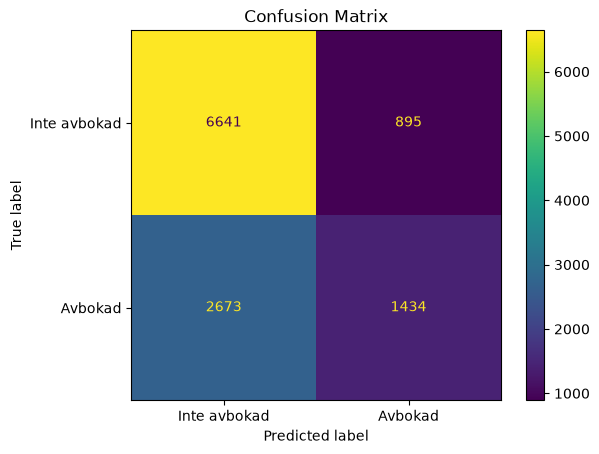

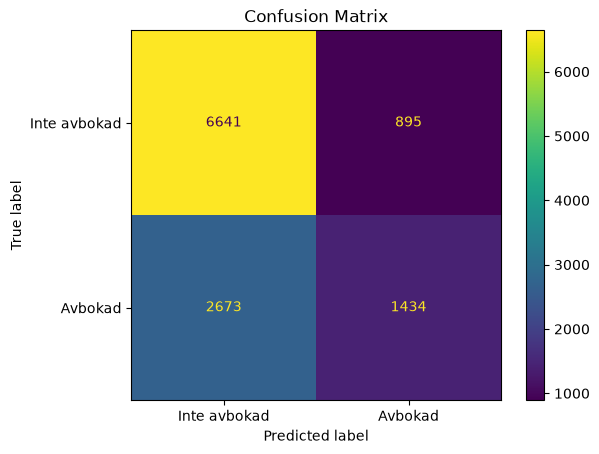

In [12]:
from src.evaluation import plot_confusion_matrix

# Visualiserar modellens förutsägelser mot facit
# y_val = verkliga utfall
# y_pred = de 20 % bokningar som har högst avbokningsrisk
plot_confusion_matrix(y_val, y_pred)

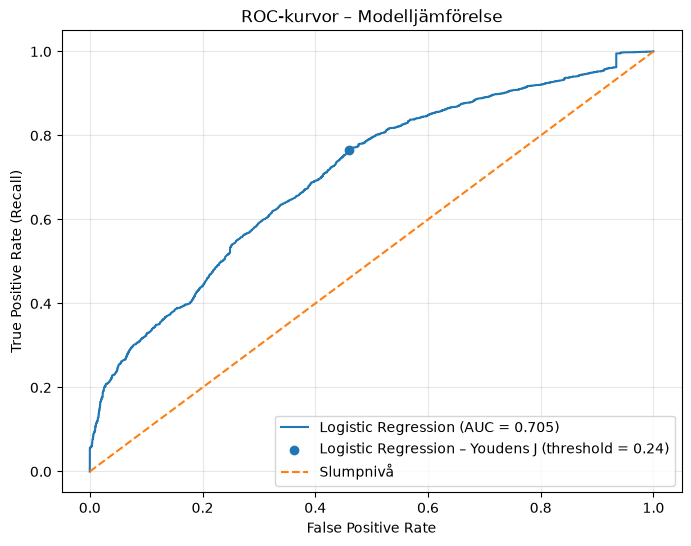

In [13]:
from src.evaluation import plot_roc_curve


# Skapar en dictionary med modellnamn och sannolikheter.
predictions = {
    "Logistic Regression": probabilities
}

# Ritar ROC-kurvan.
roc_results = plot_roc_curve(y_val, predictions)

In [14]:
# Utvärdera baseline på samma valideringsdata som Logistic Regression
baseline_results = evaluate_top_share(y_val, val["lead_time"])

# Jämför modellernas resultat
for metric in ["precision", "recall", "f1_score"]:
    print(f"{metric}: Baseline {baseline_results[metric]:.2%} | Logistic Regression {results[metric]:.2%}")

precision: Baseline 54.36% | Logistic Regression 61.57%
recall: Baseline 30.83% | Logistic Regression 34.92%
f1_score: Baseline 39.34% | Logistic Regression 44.56%
